# Лабораторная работа №1
## Низкоуровневый анализ, предобработка текста и статистическое языковое моделирование

**Датасет:** RuHateBe — русскоязычный бенчмарк hate speech ([репозиторий](https://github.com/Aniezka/hatespeech-russian), файл `balanced_RUHABE.csv` с Яндекс.Диска).
Тексты — комментарии с форумов 2ch и prodota.ru, содержащие оскорбления в адрес социальных групп. Целевой класс — `target_group` (группа, на которую направлена агрессия).

**План работы** (соответствует пунктам задания):
1. Загрузка, выбор целевой колонки, стратифицированное разбиение 80/20
2. Исследование структуры Train: объём, длины, стоп-слова
3. Выявление типов шума, характерных для домена
4. Конвейер очистки на `re` + токены `<s>` / `</s>`
5. Сравнительная нормализация: стемминг vs лемматизация
6. Расстояние Левенштейна (своя реализация, O(min(n,m)) памяти) и поиск опечаток
7. N-граммная языковая модель с явным словарём и `[UNK]`
8. Сглаживание и перплексия (без сглаживания / со сглаживанием)
9. Генерация текстов марковской цепью

Подробные рассуждения и выводы — в `README.md`.

In [1]:
import re
import math
import random
import time
import unicodedata
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
import pymorphy3

nltk.download("stopwords", quiet=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# единый стиль графиков: один цвет для величин, ненавязчивая сетка
MAIN = "#3B6EA8"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "font.size": 10,
})
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

## 1. Загрузка данных и разбиение Train / Test

Файл разделён `;`, в кодировке UTF-8 с BOM. Каждая строка — фрагмент диалога с форума:

| Колонка | Содержимое |
|---|---|
| `Reply 1 original` | исходная реплика, на которую отвечают (контекст) |
| `Reply 2 original` | ответ на неё — оригинальный, неочищенный текст, содержащий оскорбление |
| `Identifiers` | ключевые слова (оскорбления), по которым строка попала в датасет |
| `target_group` | группа, на которую направлена агрессия |
| `Reply 2 original dialogue 1/2` | короткие вежливые реплики-ответы на `Reply 1` (судя по стилю — сгенерированные, нетоксичные альтернативы); с оригинальным текстом не пересекаются |

Целевая текстовая колонка — `Reply 2 original`: это единственный «живой» текст с форума, к которому относится разметка (ключевое слово из `Identifiers` встречается в нём в ~77% строк, а в `Reply 1` — лишь в ~9%). Колонка `target_group` — класс для стратификации.

In [2]:
DATA_PATH = "data/balanced_RUHABE.csv"
raw = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig", index_col=0)
print("Размер:", raw.shape)
print("Колонки:", list(raw.columns))
raw.head(3)

Размер: (10382, 6)
Колонки: ['Reply 1 original', 'Reply 2 original', 'Identifiers', 'target_group', 'Reply 2 original dialogue 1', 'Reply 2 original dialogue 2']


,Reply 1 original,Reply 2 original,Identifiers,target_group,Reply 2 original dialogue 1,Reply 2 original dialogue 2
0,150 м Когда мужики спокойно за 250 прыгают. Пиздомрази и тут не конкурентноспособны. Все равно что с детьми соревнов...,Слышишь блядь заткни свой ебальник сука,"блядь, сука",women,Это ты сейчас о чём?,"Вот они и хотят быть равноправными участниками игр, а для этого нужно научиться уважать друг друга 🙂"
1,"журналюхи развели проф. Бабуина на разговор о керченском стрелке, вроде бы даже не предупредив, что это пойдёт в эфи...",я высказал предположение что ... но естественно это не проверить не узнать об этом это уже ничего не возможно Хаха ...,"блядь, сука",women,Такое случается и в жизни 🙁Лучше поменьше читать жёлтую прессу😉,"Мне кажется, тут неуместно говорить «педераст» и употреблять слово «хулиган»"
2,Возможности карьеры 1991 Прям про двачера для двачеров,БЛЯДЬ СУКА ПИЗДЕЦ ВОТ ПОВЕЗЛО ЕБАНЫЙ РОТ ЗА ЧТО ЕМУ БЛЯ КАК ЖЕХОЧЕТСЯ ВОТ ТАК ЖЕ ЧТОБ НИХУЯ НИХУЯ И ПОТОМ НА ГОЛОВУ ...,"блядь, сука",women,А что случилось с твоими возможностями в 1991 году?,А сейчас у тебя какая карьера?


In [3]:
TEXT_COL = "Reply 2 original"
LABEL_COL = "target_group"

print(raw[LABEL_COL].value_counts())

target_group
man           2456
women         2025
other         1917
born_place    1827
lgbt          1180
migrants       531
child          421
migrant         25
Name: count, dtype: int64


In [4]:
top_ids = (raw.groupby(LABEL_COL)["Identifiers"]
              .agg(lambda s: ", ".join(f"{k} ({v})" for k, v in s.value_counts().head(4).items())))
print(top_ids.to_string())

one_class = (raw.groupby("Identifiers")[LABEL_COL].nunique() == 1).mean()
print(f"\nНаборов Identifiers: {raw['Identifiers'].nunique()}, "
      f"из них однозначно задают класс: {one_class:.1%}")

target_group
born_place         хохол (1030), чурка (159), жид (153), пиндос (109)
child         выблядок (215), пиздюк (84), выродок (35), школота (18)
lgbt            пидорас (328), пидор (208), петух (158), хуесос (140)
man               жид (173), пидор (170), пидорас (146), хуесос (131)
migrant                                     обезьяна (24), черныш (1)
migrants            чурка (172), хач (91), пиздоглазый (50), абу (36)
other          дегенерат (323), пидорас (234), мразь (222), чмо (196)
women                 блядь (603), сука (499), шлюха (498), дура (88)

Наборов Identifiers: 537, из них однозначно задают класс: 94.8%


**Метки шумные.** Класс `target_group`, судя по всему, выведен из ключевых слов, а не размечен по смыслу: набор `Identifiers` почти всегда однозначно определяет класс. Например, «блядь», «сука» → `women`, хотя в первых примерах выше эти слова — просто междометия без агрессии к женщинам. Одни и те же слова («пидор», «хуесос») встречаются в разных классах (`lgbt`, `man`, `other`).

В этой работе класс используется только для стратификации разбиения, поэтому шум на результаты не влияет. Для задач классификации он ограничивал бы достижимое качество.

В разметке есть опечатка: 25 строк с классом `migrant` при основном `migrants` — сливаем. Кроме того, в файле много полных дубликатов текста (один и тот же ответ встречается в нескольких диалогах). Дубликаты удаляем **до** разбиения, иначе одинаковые документы попадут и в Train, и в Test, и перплексия языковой модели будет нечестно занижена. При этом у многих повторяющихся текстов копии размечены **разными** классами — ещё одно подтверждение шумности меток; `drop_duplicates` оставляет метку первой копии, для стратификации этого достаточно.

In [5]:
df = raw[[TEXT_COL, LABEL_COL]].copy()
df[LABEL_COL] = df[LABEL_COL].replace({"migrant": "migrants"})
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()

n_before = len(df)
dup_groups = df.groupby(TEXT_COL)[LABEL_COL].agg(["size", "nunique"])
dup_groups = dup_groups[dup_groups["size"] > 1]
print(f"Текстов с повторами: {len(dup_groups)} (до {dup_groups['size'].max()} копий), "
      f"из них с разными метками у копий: {(dup_groups['nunique'] > 1).sum()}")
df = df[df[TEXT_COL].str.len() > 0]
df = df.drop_duplicates(subset=TEXT_COL).reset_index(drop=True)
print(f"Строк до очистки дубликатов: {n_before}, после: {len(df)} (удалено {n_before - len(df)})")

train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df[LABEL_COL], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_stats = pd.DataFrame({
    "train": train_df[LABEL_COL].value_counts(),
    "test": test_df[LABEL_COL].value_counts(),
})
split_stats["train_%"] = (100 * split_stats["train"] / split_stats["train"].sum()).round(1)
split_stats["test_%"] = (100 * split_stats["test"] / split_stats["test"].sum()).round(1)
print(f"Train: {len(train_df)} документов, Test: {len(test_df)} документов")
split_stats

Текстов с повторами: 2115 (до 13 копий), из них с разными метками у копий: 1328
Строк до очистки дубликатов: 10382, после: 7270 (удалено 3112)
Train: 5816 документов, Test: 1454 документов


,train,test,train_%,test_%
target_group,,,,
man,1462,365,25.1,25.1
women,1375,344,23.6,23.7
other,979,245,16.8,16.9
born_place,864,216,14.9,14.9
lgbt,561,140,9.6,9.6
child,301,75,5.2,5.2
migrants,274,69,4.7,4.7


## 2. Исследование структуры данных (только Train)

Все статистики ниже считаются **строго на обучающей выборке**, чтобы информация из Test никак не влияла на решения по предобработке.

In [6]:
train_texts = train_df[TEXT_COL].tolist()

len_words = np.array([len(t.split()) for t in train_texts])
len_chars = np.array([len(t) for t in train_texts])

summary = pd.DataFrame({
    "слов": [len_words.mean(), np.median(len_words), len_words.min(), len_words.max()],
    "символов": [len_chars.mean(), np.median(len_chars), len_chars.min(), len_chars.max()],
}, index=["среднее", "медиана", "минимум", "максимум"]).round(1)

print(f"Количество документов в Train: {len(train_texts)}")
print(f"Всего слов (по пробелам): {len_words.sum()}")
summary

Количество документов в Train: 5816
Всего слов (по пробелам): 163365


,слов,символов
среднее,28.1,171.2
медиана,23.0,137.0
минимум,2.0,24.0
максимум,94.0,517.0


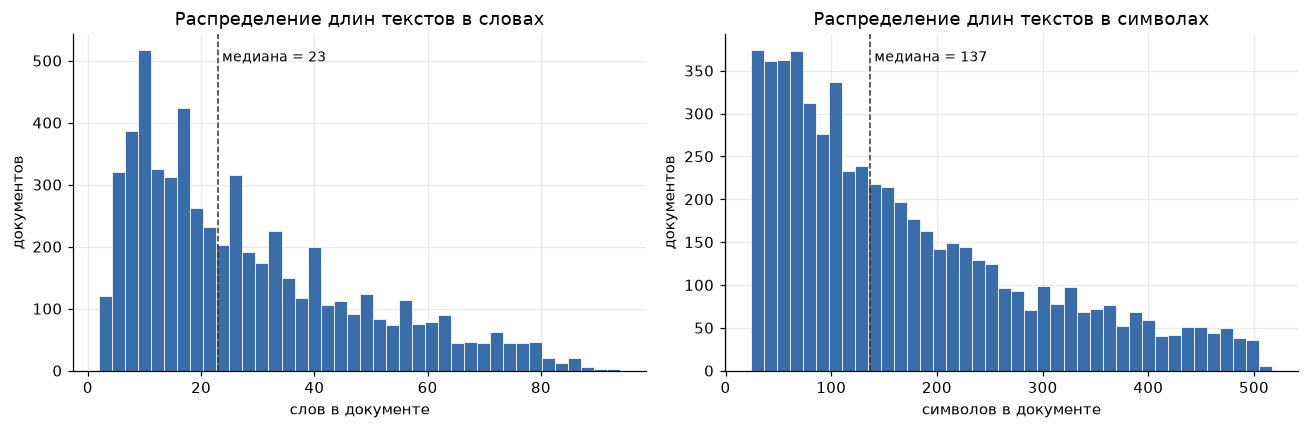

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title, xlabel in [
    (axes[0], len_words, "Распределение длин текстов в словах", "слов в документе"),
    (axes[1], len_chars, "Распределение длин текстов в символах", "символов в документе"),
]:
    ax.hist(data, bins=40, color=MAIN, edgecolor="white", linewidth=0.5)
    ax.axvline(np.median(data), color="#333", linestyle="--", linewidth=1)
    ax.text(np.median(data), ax.get_ylim()[1] * 0.95, f" медиана = {np.median(data):.0f}", va="top", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("документов")
plt.tight_layout()
plt.show()

### Стоп-слова
Для подсчёта используем список русских стоп-слов из NLTK (151 слово). Токенизация для этого шага — простая: последовательности кириллических букв в нижнем регистре.

Стоп-слов в списке NLTK: 151
Всего кириллических токенов: 161885
Из них стоп-слов: 60582 (37.4%)


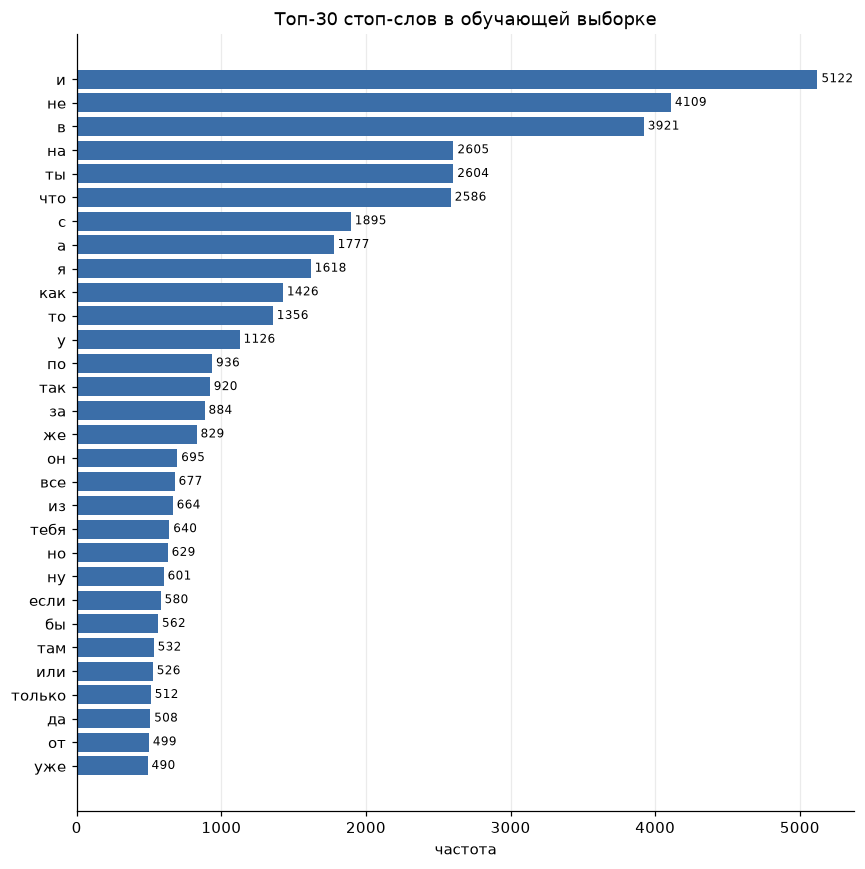

In [8]:
RU_STOPWORDS = set(stopwords.words("russian"))
print(f"Стоп-слов в списке NLTK: {len(RU_STOPWORDS)}")

simple_tok = re.compile(r"[а-яё]+")
all_tokens_raw = [w for t in train_texts for w in simple_tok.findall(t.lower())]
stop_counts = Counter(w for w in all_tokens_raw if w in RU_STOPWORDS)

print(f"Всего кириллических токенов: {len(all_tokens_raw)}")
print(f"Из них стоп-слов: {sum(stop_counts.values())} ({100*sum(stop_counts.values())/len(all_tokens_raw):.1f}%)")

top30 = stop_counts.most_common(30)
words, freqs = zip(*top30)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(range(len(words))[::-1], freqs, color=MAIN)
ax.set_yticks(range(len(words))[::-1])
ax.set_yticklabels(words)
for i, f in zip(range(len(words))[::-1], freqs):
    ax.text(f, i, f" {f}", va="center", fontsize=8)
ax.set_title("Топ-30 стоп-слов в обучающей выборке")
ax.set_xlabel("частота")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [9]:
# Проверяем готовый список на нашем домене: какие частые слова Train в него НЕ попали
word_counts = Counter(all_tokens_raw)
missing = [(w, n) for w, n in word_counts.most_common(50) if w not in RU_STOPWORDS]
print("Частые слова Train вне списка NLTK:", missing)

# Доменный вариант списка: добавляем пропущенные служебные слова и,
# наоборот, оставляем в тексте обращения на «ты/вы» и отрицания — в оскорблениях они несут смысл
EXTRA_STOP = {"это"}
KEEP = {"ты", "тебя", "тебе", "вы", "вас", "вам", "не", "нет", "ни"}
DOMAIN_STOPWORDS = (RU_STOPWORDS | EXTRA_STOP) - KEEP

n_tok = len(all_tokens_raw)
for name, sw in [("NLTK", RU_STOPWORDS), ("доменный", DOMAIN_STOPWORDS)]:
    share = sum(word_counts[w] for w in sw) / n_tok
    print(f"Список {name:8s}: {len(sw)} слов, покрывает {share:.1%} токенов Train")
print("Сохраняем в тексте:", ", ".join(f"{w} ({word_counts[w]})" for w in sorted(KEEP, key=lambda w: -word_counts[w])))

Частые слова Train вне списка NLTK: [('это', 1598), ('просто', 584), ('блядь', 522), ('тебе', 486), ('нахуй', 431), ('сука', 419)]
Список NLTK    : 151 слов, покрывает 37.4% токенов Train
Список доменный: 144 слов, покрывает 33.3% токенов Train
Сохраняем в тексте: не (4109), ты (2604), тебя (640), тебе (486), нет (372), вы (267), ни (161), вас (104), вам (53)


**Готовый список не абсолютен.** Проверка на Train показывает пробелы NLTK: в нём нет «это» (одно из самых частых служебных слов) и нет «тебе», хотя «тебя» есть; зато внутри лежат смысловые «хорошо», «лучше», «конечно», «два», «три». Кроме того, для hate speech часть стоп-слов важна: высокая позиция «ты»/«тебя» в топе — это прямые обращения к собеседнику, типичные для оскорблений («ты дебил»), а отрицания «не»/«нет» переворачивают смысл высказывания.

Поэтому собран доменный список `DOMAIN_STOPWORDS`: NLTK + «это», минус обращения на «ты/вы» и отрицания.

**Где стоп-слова применяются.** В этой работе — нигде, кроме анализа: N-граммная языковая модель моделирует порядок **всех** слов, и удаление служебных слов сломало бы грамматику и смысл («ты не прав» превратилось бы в «прав»), а сгенерированные тексты стали бы нечитаемыми. Доменный список пригодится в задачах, где важны не порядок, а набор слов — например, при классификации по мешку слов / TF-IDF.

## 3. Анализ шума в текстах

Домен — форумные комментарии (2ch, prodota), поэтому проверяем как «классические» типы шума (URL, HTML, упоминания, e-mail), так и специфичные для имиджборд: растянутые буквы («блиииин»), эмоциональную пунктуацию («!!!», «?!»), текстовые смайлы из скобок («)))»), капс, латиницу (ники, игровой сленг), подмену русских букв латинскими, эмодзи, числа. Для каждого типа считаем, в скольких документах Train он встречается, и показываем примеры совпадений.

In [10]:
NOISE_PATTERNS = {
    "URL":                    r"(?:https?://|www\.)\S+",
    "HTML-теги":              r"<[^>]+>",
    "HTML-сущности":          r"&(?:[a-zA-Z]+|#\d+);",
    "e-mail":                 r"[\w.+-]+@[\w-]+\.[a-zA-Z]{2,}",
    "@ник (латиница вплотную)": r"(?<![\w.])@[A-Za-z_]\w*",
    "символ @ (разделитель @-паст)": r"\S{0,12}@\S{0,12}",
    "#хэштеги":               r"#\w+",
    "эмодзи":                 r"[\U0001F000-\U0001FAFF☀-➿⬀-⯿]",
    "скобочные смайлы )))/(((": r"[:;]-?[()]+|\){2,}|\({2,}",
    "«эхо» (((слово)))":      r"\({3}\s*[\w-]+\s*\){3}",
    "числа":                  r"\d+",
    "латиница (слова)":       r"\b[A-Za-z]{2,}\b",
    "смешение алфавитов в слове": r"\b(?=\w*[А-Яа-яЁё])(?=\w*[A-Za-zë])\w+\b",
    "КАПС (слово из 3+ заглавных)": r"\b[А-ЯЁ]{3,}\b",
    "растянутые буквы (3+)":  r"([А-Яа-яЁё])\1{2,}",
    "эмоциональная пунктуация (!!, ?!)": r"[!?]{2,}",
    "многоточия":             r"\.{2,}|…",
    "переводы строк / табы":  r"[\n\r\t]",
    "неразрывный пробел":     r" ",
    "двойные пробелы":        r" {2,}",
}

rows = []
for name, pat in NOISE_PATTERNS.items():
    rx = re.compile(pat)
    hits = [(t, rx.findall(t)) for t in train_texts if rx.search(t)]
    examples = []
    for t, found in hits[:200]:
        for m in rx.finditer(t):
            examples.append(m.group(0))
            if len(examples) >= 4:
                break
        if len(examples) >= 4:
            break
    rows.append({
        "тип шума": name,
        "документов": len(hits),
        "% документов": round(100 * len(hits) / len(train_texts), 2),
        "примеры": ", ".join(repr(e) for e in dict.fromkeys(examples)),
    })
noise_table = pd.DataFrame(rows).sort_values("документов", ascending=False).reset_index(drop=True)
noise_table

,тип шума,документов,% документов,примеры
0,числа,1123,19.31,"'911', '9', '11', '100'"
1,КАПС (слово из 3+ заглавных),754,12.96,"'БУДУТ', 'ВЕЛИКИМ', 'БОГОВ', 'ЧОТ'"
2,неразрывный пробел,225,3.87,'\xa0'
3,латиница (слова),210,3.61,"'jpg', 'webm', 'Death', 'Watch'"
4,растянутые буквы (3+),205,3.52,"'ррр', 'яяяя', 'ииииииииииииииииииииииииииииииии', 'ИИИ'"
5,многоточия,176,3.03,'...'
6,"эмоциональная пунктуация (!!, ?!)",136,2.34,"'!!!', '?!!!', '!!!!!'"
7,двойные пробелы,117,2.01,' '
8,скобочные смайлы )))/(((,103,1.77,"')))', '))'"
9,смешение алфавитов в слове,54,0.93,"'темыhi', 'oooohhhhпросто', 'Укрaбина', 'укрaбинцы'"


**Символы вне «нормального» алфавита.** Чтобы убедиться, что мы ничего не пропустили, посмотрим на все символы, которые не являются кириллицей, латиницей, цифрами, пробелом или базовой пунктуацией.

In [11]:
allowed = re.compile(r"[А-Яа-яЁёA-Za-z0-9\s.,!?;:\"'()\-]")
odd_chars = Counter(ch for t in train_texts for ch in t if not allowed.match(ch))
odd_table = pd.DataFrame(
    [(ch, f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), c) for ch, c in odd_chars.most_common(25)],
    columns=["символ", "код", "название", "частота"],
)
print(f"Уникальных «нестандартных» символов: {len(odd_chars)}, всего вхождений: {sum(odd_chars.values())}")
odd_table

Уникальных «нестандартных» символов: 46, всего вхождений: 777


,символ,код,название,частота
0,/,U+002F,SOLIDUS,183
1,+,U+002B,PLUS SIGN,110
2,%,U+0025,PERCENT SIGN,90
3,@,U+0040,COMMERCIAL AT,60
4,=,U+003D,EQUALS SIGN,55
5,—,U+2014,EM DASH,39
6,«,U+00AB,LEFT-POINTING DOUBLE ANGLE QUOTATION MARK,32
7,»,U+00BB,RIGHT-POINTING DOUBLE ANGLE QUOTATION MARK,31
8,\,U+005C,REVERSE SOLIDUS,24
9,_,U+005F,LOW LINE,15


**Вывод по шуму.** Классические веб-артефакты (URL, HTML-теги и сущности, переводы строк) в датасете **отсутствуют** — регулярные выражения дали 0 совпадений; авторы датасета вычистили их при сборе. Зато присутствует много шума, характерного именно для форумного домена:

1. **числа** (в т.ч. с суффиксами: «8-й», «2ch», «250к») — самый массовый тип;
2. **КАПС** — крик, частый в агрессивных репликах и «пастах»;
3. **эмоциональная пунктуация** («!!!», «?!») и **многоточия**;
4. **латиница** — ники, игровые термины, английские вставки;
5. **растянутые буквы** («сукааа», «нууу») — эмоциональное удлинение, порождает псевдо-уникальные слова;
6. **скобочные смайлы** «)))» / «(((» — в этом домене чаще издёвка, чем радость («тупой хохол)))»);
7. **символ @** — вопреки ожиданиям, это **не упоминания**: на 2ch `@` разделяет пункты в «@-пастах» («ПЫТАЕШЬСЯ ШУТИТЬ@ВЫГЛЯДИШЬ КАК КЛОУН»). Настоящих @-ников вплотную к имени нет, есть один e-mail;
8. **смешение алфавитов** в одном слове: часть — слипшиеся слова («темыhi»), но часть — русские буквы, подменённые латинскими двойниками («Укрaбина», «прoлaпсошизикe», «всë»): обход фильтров модерации, типичный именно для hate speech;
9. **«эхо» (((слово)))** — известный антисемитский маркер; редкий, но показательный для домена;
10. **эмодзи, #хэштеги, типографика** («ёлочки», длинные тире, неразрывные пробелы) — редко.

Каждый тип получит своё правило в конвейере. КАПС — исключение: регистр приводится к нижнему, чтобы «БЛЯДЬ» и «блядь» были одним словом, а метка перед каждым словом капсом раздула бы текст. Доля капса — полезный признак для будущей классификации, но в языковую модель он не попадает.

## 4. Конвейер очистки текста

Принципы:
- каждый тип шума обрабатывается **отдельным правилом** в фиксированном порядке;
- то, что несёт сигнал для языковой модели как *класс* (числа, латиница, ссылки, ники, эмодзи), заменяется на **специальный токен** — так модель учит, что «после “купил за” идёт число», не размазывая вероятность по тысячам разных чисел;
- **эмоциональные сигналы сохраняются токенами**, а не удаляются: «!!», «?!» → `[EMPH]`, «)))» → `[SMILE]`, «(((» → `[SAD]`, «(((слово)))» → `[ECHO] слово`. Для человека это явные маркеры агрессии, издёвки и ненависти, и модель тоже должна их видеть;
- `@` вне e-mail и ников — это разделитель, заменяется пробелом;
- латинские двойники внутри русских слов («Укрaбина») переводятся в кириллицу — иначе слово разрежется на куски;
- растянутые буквы **схлопываются** («сукааа» → «сука»), а не удаляются — иначе слово теряется;
- `ё → е`: в форумном тексте обе формы используются вперемешку («ещё»/«еще»), это раздувает словарь;
- остальная пунктуация (в т.ч. одиночные «!», «?», многоточия) удаляется в самом конце — только после того, как все «содержательные» классы уже обработаны;
- каждому документу добавляются технические токены `<s>` и `</s>`.
**Leet перед числами:** отдельные цифры внутри кириллических слов заменяются на похожие буквы (`стукач0к → стукачок`). Требуется минимум 4 русские буквы, слово начинается и заканчивается буквой. Записи `5ооо`, `250к`, `т90`, `ак74м` это правило не меняет; далее применяется обычная обработка чисел. Это ограниченная эвристика: латинские ники и неоднозначные варианты leet автоматически не расшифровываются.


In [12]:
# Правила применяются последовательно, порядок важен:
# e-mail раньше @, «эхо» раньше смайлов, числа и двойники раньше латиницы (чтобы "2ch" и "Укрaбина" не распались)

# латинские буквы, неотличимые на глаз от русских
HOMOGLYPHS = str.maketrans("aeopcxykmtë", "аеорсхукмтё")

def fix_homoglyphs(m: re.Match) -> str:
    w = m.group(0)
    if re.search(r"[а-яё]", w) and re.search(r"[a-zë]", w):
        return w.translate(HOMOGLYPHS)
    return w

# Консервативный русский leet: только отдельные цифры ВНУТРИ слова.
# Не трогаем записи с цифрой в начале/конце и группы цифр: 5ооо, 250к, т90, ак74м.
# Это эвристика, а не универсальная расшифровка ников и латинского leet.
LEET_TABLE = str.maketrans({"0": "о", "1": "и", "3": "з", "4": "ч",
                            "6": "б", "7": "т", "8": "в"})

def fix_leet(m: re.Match) -> str:
    w = m.group(0)
    if (re.fullmatch(r"[а-яё]+(?:[0134678][а-яё]+)+", w)
            and len(re.findall(r"[а-яё]", w)) >= 4):
        return w.translate(LEET_TABLE)
    return w

CLEAN_RULES = [
    ("неразрывные пробелы и управляющие символы", re.compile(r"[\u00a0\r\n\t]+"), " "),
    ("URL → [URL]",                  re.compile(r"(?:https?://|www\.)\S+"), " [URL] "),
    ("e-mail → [EMAIL]",             re.compile(r"[\w.+-]+@[\w-]+\.[a-z]{2,}"), " [EMAIL] "),
    ("HTML-теги → удалить",          re.compile(r"<[^>]+>"), " "),
    ("HTML-сущности → удалить",      re.compile(r"&(?:[a-z]+|#\d+);"), " "),
    ("@ник латиницей → [USER]",      re.compile(r"(?<![\w.])@[a-z_]\w*"), " [USER] "),
    ("@ как разделитель → пробел",   re.compile(r"@"), " "),
    ("#хэштеги → [TAG]",             re.compile(r"#\w+"), " [TAG] "),
    ("«эхо» (((слово))) → [ECHO] слово", re.compile(r"\({3}\s*([\w-]+)\s*\){3}"), r" [ECHO] \1 "),
    ("смайлы ))) и :) → [SMILE]",    re.compile(r"[:;]-?\)+|\){2,}"), " [SMILE] "),
    ("смайлы ((( и :( → [SAD]",      re.compile(r"[:;]-?\(+|\({2,}"), " [SAD] "),
    ("эмодзи → [EMOJI]",             re.compile(r"[\U0001F000-\U0001FAFF☀-➿⬀-⯿]️?"), " [EMOJI] "),
    ("!!, ?!, ??? → [EMPH]",         re.compile(r"[!?]{2,}"), " [EMPH] "),
    ("leet внутри русских слов → буквы", re.compile(r"\b[а-яё0-9]+\b"), fix_leet),
    ("числа (с хвостами вроде 8-й, 2ch) → [NUM]", re.compile(r"\d+(?:[.,:]\d+)*[\w-]*"), " [NUM] "),
    ("латинские двойники в русских словах → кириллица", re.compile(r"[a-zа-яёë]+"), fix_homoglyphs),
    ("латинские слова → [LAT]",      re.compile(r"[a-z]+(?:['’-][a-z]+)*"), " [LAT] "),
    ("растянутые буквы: 3+ подряд → 1", re.compile(r"([а-яё])\1{2,}"), r"\1"),
    ("ё → е",                        re.compile(r"ё"), "е"),
]

# итоговая токенизация: спец-токены или кириллические слова (в т.ч. через дефис)
TOKEN_RE = re.compile(r"\[[A-Z]+\]|[а-я]+(?:-[а-я]+)*")

def clean_text(text: str, verbose: bool = False) -> str:
    # Нижний регистр ДО правил: латиница и ё ищутся в нижнем регистре,
    # а спец-токены вставляются в верхнем и потому не трогаются последующими правилами.
    t = text.lower()
    for name, rx, repl in CLEAN_RULES:
        new_t = rx.sub(repl, t)
        if verbose and new_t != t:
            print(f"  [{name}]\n    {new_t.strip()}")
        t = new_t
    # Остальная пунктуация и прочие символы не несут смысла для словарной N-граммной модели —
    # удаляются на последнем шаге просто за счёт того, что токенизатор их не извлекает.
    tokens = TOKEN_RE.findall(t)
    return "<s> " + " ".join(tokens) + " </s>"

def tokenize(cleaned: str) -> list[str]:
    return cleaned.split()

demo = [
    "стукач0к, пр1вет, сл0во; 5ооо рублей, 250к, т90, ак74м",
    "Слышишь блядь!!! Заткни свой ебальник, сука... 🙂",
    "журналюхи развели проф. Бабуина на разговор о керченском стрелке (но это не точно)",
    "@vasya ну ты и лоооох, GG WP, 2ch рулит, купил за 250к #позор",
    "ПЫТАЕШЬСЯ ШУТИТЬ@ВЫГЛЯДИШЬ КАК КЛОУН))) а Укрaбина всë?! пиши на anon@yandex.ru",
    "опять эти (((Иваны))) виноваты, ну ок((",
    "Ещё раз: 8-й титул взял без конкуренции — и что?",
]
for d in demo:
    print("ИСХОДНЫЙ:", d)
    print("→", clean_text(d))
    print()

ИСХОДНЫЙ: стукач0к, пр1вет, сл0во; 5ооо рублей, 250к, т90, ак74м
→ <s> стукачок привет слово [NUM] рублей [NUM] т [NUM] ак [NUM] </s>

ИСХОДНЫЙ: Слышишь блядь!!! Заткни свой ебальник, сука... 🙂
→ <s> слышишь блядь [EMPH] заткни свой ебальник сука [EMOJI] </s>

ИСХОДНЫЙ: журналюхи развели проф. Бабуина на разговор о керченском стрелке (но это не точно)
→ <s> журналюхи развели проф бабуина на разговор о керченском стрелке но это не точно </s>

ИСХОДНЫЙ: @vasya ну ты и лоооох, GG WP, 2ch рулит, купил за 250к #позор
→ <s> [USER] ну ты и лох [LAT] [LAT] [NUM] рулит купил за [NUM] [TAG] </s>

ИСХОДНЫЙ: ПЫТАЕШЬСЯ ШУТИТЬ@ВЫГЛЯДИШЬ КАК КЛОУН))) а Укрaбина всë?! пиши на anon@yandex.ru
→ <s> пытаешься шутить выглядишь как клоун [SMILE] а украбина все [EMPH] пиши на [EMAIL] </s>

ИСХОДНЫЙ: опять эти (((Иваны))) виноваты, ну ок((
→ <s> опять эти [ECHO] иваны виноваты ну ок [SAD] </s>

ИСХОДНЫЙ: Ещё раз: 8-й титул взял без конкуренции — и что?
→ <s> еще раз [NUM] титул взял без конкуренции и что </s

In [13]:
print("Пошаговая трассировка правил на одном примере:")
print("ИСХОДНЫЙ:", demo[3])
print("→", clean_text(demo[3], verbose=True))

Пошаговая трассировка правил на одном примере:
ИСХОДНЫЙ: @vasya ну ты и лоооох, GG WP, 2ch рулит, купил за 250к #позор
  [@ник латиницей → [USER]]
    [USER]  ну ты и лоооох, gg wp, 2ch рулит, купил за 250к #позор
  [#хэштеги → [TAG]]
    [USER]  ну ты и лоооох, gg wp, 2ch рулит, купил за 250к  [TAG]
  [числа (с хвостами вроде 8-й, 2ch) → [NUM]]
    [USER]  ну ты и лоооох, gg wp,  [NUM]  рулит, купил за  [NUM]   [TAG]
  [латинские слова → [LAT]]
    [USER]  ну ты и лоооох,  [LAT]   [LAT] ,  [NUM]  рулит, купил за  [NUM]   [TAG]
  [растянутые буквы: 3+ подряд → 1]
    [USER]  ну ты и лох,  [LAT]   [LAT] ,  [NUM]  рулит, купил за  [NUM]   [TAG]
→ <s> [USER] ну ты и лох [LAT] [LAT] [NUM] рулит купил за [NUM] [TAG] </s>


In [14]:
train_df["clean"] = train_df[TEXT_COL].map(clean_text)
test_df["clean"] = test_df[TEXT_COL].map(clean_text)
train_tokens = [tokenize(c) for c in train_df["clean"]]
test_tokens = [tokenize(c) for c in test_df["clean"]]

SPECIAL = {"<s>", "</s>", "[URL]", "[EMAIL]", "[USER]", "[TAG]", "[EMOJI]", "[NUM]", "[LAT]",
           "[EMPH]", "[SMILE]", "[SAD]", "[ECHO]", "[UNK]"}
special_counts = Counter(t for doc in train_tokens for t in doc if t in SPECIAL)
print("Специальные токены в Train:", dict(special_counts))
print()
print("Пример очищенного документа из Train:")
print(train_df.loc[0, TEXT_COL])
print("→", train_df.loc[0, "clean"])

Специальные токены в Train: {'<s>': 5816, '</s>': 5816, '[NUM]': 1811, '[LAT]': 622, '[EMPH]': 169, '[SMILE]': 107, '[TAG]': 5, '[ECHO]': 5, '[SAD]': 13, '[EMOJI]': 21, '[EMAIL]': 1}

Пример очищенного документа из Train:
блять, внимания мрази захотелось, понял что на него внимания не обращают нахуя ты меня суммонишь, ничтожество сидишь пукаешь тут, ну хуй с тобой, мало ли человеку нечем заняться но ты блять имей хотя бы совесть никого напрямую не доебывать
→ <s> блять внимания мрази захотелось понял что на него внимания не обращают нахуя ты меня суммонишь ничтожество сидишь пукаешь тут ну хуй с тобой мало ли человеку нечем заняться но ты блять имей хотя бы совесть никого напрямую не доебывать </s>


## 5. Сравнительная нормализация: стемминг vs лемматизация

- **Стемминг** — `SnowballStemmer("russian")` из NLTK: эвристически отрезает окончания.
- **Лемматизация** — `pymorphy3` (словарь OpenCorpora): приводит слово к нормальной форме по морфологическому анализу.

Сравниваем размер словаря (число уникальных токенов) до и после каждого метода. Спец-токены исключаем из подсчёта — они одинаковы для всех вариантов.

In [15]:
stemmer = SnowballStemmer("russian")
morph = pymorphy3.MorphAnalyzer()

word_freq = Counter(t for doc in train_tokens for t in doc if t not in SPECIAL)
vocab_raw = set(word_freq)

# нормализуем один раз на словаре, а не на каждом вхождении: так в сотни раз быстрее
t0 = time.time()
stem_map = {w: stemmer.stem(w) for w in vocab_raw}
t_stem = time.time() - t0
t0 = time.time()
lemma_map = {w: morph.parse(w)[0].normal_form for w in vocab_raw}
t_lemma = time.time() - t0

vocab_stem = set(stem_map.values())
vocab_lemma = set(lemma_map.values())

norm_table = pd.DataFrame({
    "уникальных токенов": [len(vocab_raw), len(vocab_stem), len(vocab_lemma)],
    "сокращение словаря, %": [0, round(100 * (1 - len(vocab_stem) / len(vocab_raw)), 1),
                              round(100 * (1 - len(vocab_lemma) / len(vocab_raw)), 1)],
    "время на словарь, с": [0, round(t_stem, 2), round(t_lemma, 2)],
}, index=["без нормализации", "стемминг (Snowball)", "лемматизация (pymorphy3)"])
norm_table

,уникальных токенов,"сокращение словаря, %","время на словарь, с"
без нормализации,37470,0.0,0.00
стемминг (Snowball),21571,42.4,0.28
лемматизация (pymorphy3),22666,39.5,1.38


In [16]:
# Как выглядят результаты на частых словах
sample_words = [w for w, _ in word_freq.most_common(400)][::25][:16]
pd.DataFrame({
    "слово": sample_words,
    "частота": [word_freq[w] for w in sample_words],
    "стем": [stem_map[w] for w in sample_words],
    "лемма": [lemma_map[w] for w in sample_words],
})

,слово,частота,стем,лемма
0,и,5122,и,и
1,из,579,из,из
2,есть,310,ест,есть
3,тоже,208,тож,тоже
4,того,156,тог,тот
5,похуй,123,пох,похуй
6,жизни,103,жизн,жизнь
7,сами,87,сам,сам
8,те,78,те,тот
9,чтоб,68,чтоб,чтоб


In [17]:
# Over-stemming: один стем склеивает несколько РАЗНЫХ лемм (потеря смысла)
stem_to_lemmas = defaultdict(set)
for w in vocab_raw:
    stem_to_lemmas[stem_map[w]].add(lemma_map[w])
collisions = sorted(((s, l) for s, l in stem_to_lemmas.items() if len(l) > 1),
                    key=lambda x: -len(x[1]))
print(f"Стемов, объединяющих >1 леммы: {len(collisions)} из {len(vocab_stem)}")
print("Примеры самых «жадных» стемов:")
for s, l in collisions[:8]:
    print(f"  {s!r:15} ← {sorted(l)[:8]}")

# Under-stemming: формы ОДНОГО слова (одна лемма) разошлись по разным стемам
lemma_to_stems = defaultdict(set)
for w in vocab_raw:
    lemma_to_stems[lemma_map[w]].add(stem_map[w])
split_lemmas = sorted(((l, s) for l, s in lemma_to_stems.items() if len(s) > 1), key=lambda x: -len(x[1]))
print(f"\nЛемм, чьи словоформы дали >1 стема: {len(split_lemmas)}")
for l, s in split_lemmas[:8]:
    print(f"  {l!r:15} → {sorted(s)[:8]}")

# Слова, неизвестные словарю pymorphy3 (сленг, мат, опечатки) — лемматизатор для них "угадывает"
unknown = [w for w in vocab_raw if not morph.word_is_known(w)]
print(f"\nСлов вне словаря pymorphy3: {len(unknown)} ({100*len(unknown)/len(vocab_raw):.1f}% словаря)")
print("Примеры:", sorted(unknown, key=lambda w: -word_freq[w])[:20])

Стемов, объединяющих >1 леммы: 2383 из 21571
Примеры самых «жадных» стемов:
  'еб'            ← ['еба', 'ебася', 'ебесться', 'еби', 'ебит', 'ебить', 'ебиться', 'ебу']
  'ебл'           ← ['ебить', 'еблася', 'еблеять', 'ебло', 'еблом', 'еблось', 'еблый', 'ебль']
  'еба'           ← ['ебал', 'ебалася', 'ебали', 'ебало', 'ебан', 'ебанный', 'ебать', 'ебаться']
  'ебуч'          ← ['ебуч', 'ебуча', 'ебучаять', 'ебучего', 'ебучий', 'ебучить', 'ебучих', 'ебучуять']
  'хуесос'        ← ['хуесос', 'хуесоса', 'хуесосама', 'хуесосать', 'хуесосила', 'хуесосит', 'хуесосить', 'хуесосова']
  'а'             ← ['а', 'аа', 'аи', 'ай', 'ао', 'ау', 'аы', 'ая']
  'он'            ← ['он', 'она', 'онема', 'онемой', 'они', 'оно', 'оный']
  'го'            ← ['го', 'гоев', 'гои', 'гой', 'гоу', 'гою', 'гоя']

Лемм, чьи словоформы дали >1 стема: 1384
  'дать'          → ['да', 'дав', 'дад', 'дадут', 'дайт', 'дал', 'дам', 'дан']
  'какой-то'      → ['какая-т', 'какие-т', 'каким-т', 'какими-т', 'каких-т', 'какого

In [18]:
# Где именно методы расходятся: словарные слова vs слова вне словаря pymorphy3
known = {w for w in vocab_raw if morph.word_is_known(w)}
oov = vocab_raw - known
# гибрид: лемма для словарных слов, стем — для остальных
hybrid_map = {w: lemma_map[w] if w in known else stem_map[w] for w in vocab_raw}

rows = []
for name, words in [("словарные", known), ("вне словаря", oov), ("все", vocab_raw)]:
    n_stem = len({stem_map[w] for w in words})
    n_lemma = len({lemma_map[w] for w in words})
    n_hybrid = len({hybrid_map[w] for w in words})
    rows.append({"слова": name, "уникальных": len(words),
                 "стемминг": f"{n_stem} (−{100 * (1 - n_stem / len(words)):.1f}%)",
                 "лемматизация": f"{n_lemma} (−{100 * (1 - n_lemma / len(words)):.1f}%)",
                 "гибрид": f"{n_hybrid} (−{100 * (1 - n_hybrid / len(words)):.1f}%)"})
oov_share = sum(word_freq[w] for w in oov) / sum(word_freq.values())
print(f"Слова вне словаря — {len(oov) / len(vocab_raw):.1%} словаря, но {oov_share:.1%} употреблений")
display(pd.DataFrame(rows).set_index("слова"))

# Как методы обрабатывают формы частотных слов вне словаря (мат, сленг)
for base in ["долбоеб", "хуесос", "русн", "уеб"]:
    forms = sorted((w for w in vocab_raw if w.startswith(base)), key=lambda w: -word_freq[w])[:6]
    print(f"\n{base}…: стемы → {len({stem_map[w] for w in forms})}, леммы → {len({lemma_map[w] for w in forms})}")
    for w in forms:
        print(f"   {w:12} стем={stem_map[w]:10} лемма={lemma_map[w]}")

Слова вне словаря — 27.7% словаря, но 10.8% употреблений


,уникальных,стемминг,лемматизация,гибрид
слова,,,,
словарные,27103,13715 (−49.4%),13685 (−49.5%),13685 (−49.5%)
вне словаря,10367,8347 (−19.5%),9028 (−12.9%),8347 (−19.5%)
все,37470,21571 (−42.4%),22666 (−39.5%),21862 (−41.7%)



долбоеб…: стемы → 2, леммы → 4
   долбоеб      стем=долбоеб    лемма=долбоести
   долбоебы     стем=долбоеб    лемма=долбоеб
   долбоебина   стем=долбоебин  лемма=долбоебин
   долбоебов    стем=долбоеб    лемма=долбоебова
   долбоеба     стем=долбоеб    лемма=долбоеб
   долбоебом    стем=долбоеб    лемма=долбоеб

хуесос…: стемы → 3, леммы → 5
   хуесос       стем=хуесос     лемма=хуесос
   хуесосы      стем=хуесос     лемма=хуесоса
   хуесоса      стем=хуесос     лемма=хуесоса
   хуесосина    стем=хуесосин   лемма=хуесосина
   хуесоска     стем=хуесоск    лемма=хуесоска
   хуесосить    стем=хуесос     лемма=хуесосить

русн…: стемы → 2, леммы → 5
   русня        стем=русн       лемма=руснить
   русни        стем=русн       лемма=руснуть
   руснявая     стем=русняв     лемма=руснявый
   русню        стем=русн       лемма=руснить
   русне        стем=русн       лемма=русне
   руснявый     стем=русняв     лемма=руснявыя

уеб…: стемы → 5, леммы → 5
   уебок        стем=уебок      лемма=уеб

**Выводы по нормализации.**
- **На словарных словах методы сжимают словарь одинаково** (≈ −49.5%), но лемматизация **качественнее**: она знает супплетивные формы («шёл → идти», «был → быть»), которые стеммер разносит по разным стемам, и не склеивает разные слова («он/она/оный» → стем «он»).
- **Вся разница в размере словаря — из слов вне словаря OpenCorpora** (мат, сленг, искажения — 27.7% словаря, ~11% употреблений). Здесь стемминг сжимает сильнее (−19.5% против −12.9%) и, главное, **последовательнее**: формы «долбоеб/долбоебы/долбоеба/долбоебом» сводятся к одному стему, а pymorphy3 «угадывает» для них разные и часто несуществующие леммы («долбоести», «руснить», «хуесосама»). Лемматизатор меньше «сжал» мат не потому, что бережнее с ним обращается, а потому, что **разбросал его формы** по мусорным леммам.
- Для hate speech это критично: ключевые для задачи слова — как раз оскорбления и сленг, то есть именно та часть словаря, где лемматизация слабее всего.
- **Вывод для домена:** в чистом виде ни один метод не идеален. Разумный выбор — **гибрид**: лемматизация для словарных слов (точность на нормальной лексике) и стемминг для слов вне словаря (последовательность на мате и сленге). Если выбирать один метод — для этого корпуса предпочтительнее **стемминг**: его ошибки на нормальных словах (склейки) менее вредны, чем разброс форм ключевых оскорблений у лемматизатора.
- Для языковой модели (разделы 7–9) нормализацию **не применяем**: модель должна генерировать грамматически согласованные словоформы, а не леммы или стемы.

## 6. Расстояние Левенштейна и поиск опечаток

### 6.1. Реализация
Классический алгоритм Вагнера–Фишера заполняет матрицу $(|a|+1)\times(|b|+1)$. Но для ячейки $D[i][j]$ нужны только $D[i-1][j-1]$, $D[i-1][j]$ и $D[i][j-1]$ — то есть **предыдущая строка и текущая**. Храним две строки, а более короткую строку ставим «по горизонтали»: память $O(\min(|a|,|b|))$ вместо $O(|a|\cdot|b|)$.

In [19]:
def levenshtein(a: str, b: str) -> int:
    # Память O(min(len(a), len(b))): держим только две строки матрицы,
    # причём строки индексируются более короткой из строк.
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))          # D[0][j] = j
    for i, ca in enumerate(a, start=1):
        cur = [i]                            # D[i][0] = i
        for j, cb in enumerate(b, start=1):
            cur.append(min(
                prev[j] + 1,                 # удаление
                cur[j - 1] + 1,              # вставка
                prev[j - 1] + (ca != cb),    # замена / совпадение
            ))
        prev = cur
    return prev[-1]

# проверка на известных значениях
tests = [("кот", "код", 1), ("кот", "кто", 2), ("привет", "превед", 2), ("", "абв", 3),
         ("kitten", "sitting", 3), ("сука", "сукааа", 2), ("ещё", "еще", 1), ("слово", "слово", 0)]
for a, b, expected in tests:
    got = levenshtein(a, b)
    assert got == expected, (a, b, got, expected)
    print(f"lev({a!r}, {b!r}) = {got}")
print("Все проверки пройдены.")

lev('кот', 'код') = 1
lev('кот', 'кто') = 2
lev('привет', 'превед') = 2
lev('', 'абв') = 3
lev('kitten', 'sitting') = 3
lev('сука', 'сукааа') = 2
lev('ещё', 'еще') = 1
lev('слово', 'слово') = 0
Все проверки пройдены.


### 6.2. Поиск пар с расстоянием 1–2 в корпусе

Наивный перебор всех пар словаря — это ~$V^2/2$ вызовов; при $V \approx 30\,000$ это сотни миллионов — неприемлемо для чистого Python.
Используем **индекс удалений** (идея SymSpell): для каждого слова генерируем все строки, получаемые удалением ≤2 символов; два слова с расстоянием ≤2 обязательно делят хотя бы один такой вариант. Кандидаты из одной корзины затем **проверяются** нашей функцией `levenshtein` — индекс лишь сокращает перебор, окончательный ответ даёт точный алгоритм.

Короткие слова (<4 букв) исключаем: для них пары с расстоянием 1–2 почти всегда разные слова («он/она/оно»), а не опечатки.

In [20]:
MIN_LEN = 4
words_for_search = [w for w in vocab_raw if len(w) >= MIN_LEN]
print(f"Слов длиной ≥{MIN_LEN}: {len(words_for_search)}")

def deletions(word: str, max_del: int = 2) -> set[str]:
    result = {word}
    frontier = {word}
    for _ in range(max_del):
        frontier = {w[:i] + w[i+1:] for w in frontier for i in range(len(w))}
        result |= frontier
    return result

t0 = time.time()
index = defaultdict(set)
for w in words_for_search:
    for d in deletions(w):
        index[d].add(w)

candidate_pairs = set()
for bucket in index.values():
    if len(bucket) > 1:
        for a, b in combinations(sorted(bucket), 2):
            candidate_pairs.add((a, b))
t_index = time.time() - t0

t0 = time.time()
pairs = [(a, b, levenshtein(a, b)) for a, b in candidate_pairs]
pairs = [(a, b, d) for a, b, d in pairs if 1 <= d <= 2]
t_verify = time.time() - t0

print(f"Ключей в индексе удалений: {len(index)}")
print(f"Кандидатов: {len(candidate_pairs)} (построение {t_index:.1f} с)")
print(f"Пар с расстоянием 1–2 после точной проверки: {len(pairs)} (проверка {t_verify:.1f} с)")
print(f"Из них с расстоянием 1: {sum(1 for *_, d in pairs if d == 1)}, с расстоянием 2: {sum(1 for *_, d in pairs if d == 2)}")

Слов длиной ≥4: 36284


Ключей в индексе удалений: 1205279
Кандидатов: 555279 (построение 1.5 с)
Пар с расстоянием 1–2 после точной проверки: 239093 (проверка 1.5 с)
Из них с расстоянием 1: 24398, с расстоянием 2: 214695


### 6.3. Классификация найденных пар

Не всякая пара с малым расстоянием — опечатка. Разделим найденное на три класса с помощью морфологии:
- **формы одного слова** — у обоих слов одна лемма («мужик» / «мужики»);
- **опечатка / искажение** — одно слово есть в словаре OpenCorpora, другое нет (и при этом редкое — опечатки не бывают частотными);
- **разные слова** — оба в словаре, леммы разные («кот» / «код»); это не ошибки, а «ложные друзья» метрики;
- **оба вне словаря** — сленг и мат с искажениями; морфология тут бессильна, такие пары не ранжируем.

Для опечаток ранжируем по частоте *правильного* слова (чем частотнее слово, тем вероятнее, что редкий сосед — его искажение), для форм — по суммарной частоте.

In [21]:
def classify(a, b):
    ka, kb = morph.word_is_known(a), morph.word_is_known(b)
    if ka and kb:
        return "форма" if lemma_map[a] == lemma_map[b] else "разные слова"
    if ka != kb:
        return "опечатка"
    return "оба вне словаря"

records = []
for a, b, d in pairs:
    cls = classify(a, b)
    # для опечаток ставим словарное слово первым
    if cls == "опечатка" and not morph.word_is_known(a):
        a, b = b, a
    records.append({"слово_1": a, "слово_2": b, "расстояние": d, "частота_1": word_freq[a],
                    "частота_2": word_freq[b], "класс": cls})
pairs_df = pd.DataFrame(records)
print(pairs_df["класс"].value_counts())
print("\nПары «оба вне словаря» (сленг/мат и их искажения) в таблицы не выводим — для них морфология ничего не знает.")

класс
разные слова       137924
опечатка            60231
форма               24735
оба вне словаря     16203
Name: count, dtype: int64

Пары «оба вне словаря» (сленг/мат и их искажения) в таблицы не выводим — для них морфология ничего не знает.


In [22]:
print("Топ-10 кандидатов в опечатки/искажения (слово_1 — словарное, слово_2 — вне словаря, встречается ≤3 раз):")
typos = (pairs_df[(pairs_df["класс"] == "опечатка") & (pairs_df["частота_2"] <= 3)]
         .sort_values(["расстояние", "частота_1"], ascending=[True, False])
         .head(10).reset_index(drop=True))
typos

Топ-10 кандидатов в опечатки/искажения (слово_1 — словарное, слово_2 — вне словаря, встречается ≤3 раз):


,слово_1,слово_2,расстояние,частота_1,частота_2,класс
0,тебя,утебя,1,640,1,опечатка
1,тебя,тибя,1,640,3,опечатка
2,просто,прото,1,584,3,опечатка
3,если,еслиб,1,580,3,опечатка
4,если,есле,1,580,1,опечатка
5,блядь,боядь,1,521,1,опечатка
6,блядь,блядж,1,521,3,опечатка
7,блядь,блядьа,1,521,1,опечатка
8,блядь,блядьу,1,521,1,опечатка
9,только,толко,1,511,1,опечатка


In [23]:
print("Топ-10 пар «разные формы одного слова»:")
forms = pairs_df[pairs_df["класс"] == "форма"].copy()
forms["сумм_частота"] = forms["частота_1"] + forms["частота_2"]
forms.sort_values("сумм_частота", ascending=False).head(10).reset_index(drop=True)

Топ-10 пар «разные формы одного слова»:


,слово_1,слово_2,расстояние,частота_1,частота_2,класс,сумм_частота
0,тебе,тебя,1,486,640,форма,1126
1,блядь,блять,1,521,305,форма,826
2,бляди,блядь,1,62,521,форма,583
3,блядей,блядь,2,20,521,форма,541
4,блядь,блядям,2,521,4,форма,525
5,блядь,блядью,1,521,3,форма,524
6,сука,суки,1,422,53,форма,475
7,сука,суку,1,422,10,форма,432
8,сука,суке,1,422,3,форма,425
9,сука,суками,2,422,1,форма,423


In [24]:
print("Для сравнения — «ложные друзья»: близкие по написанию, но разные словарные слова:")
others = pairs_df[pairs_df["класс"] == "разные слова"].copy()
others["мин_частота"] = others[["частота_1", "частота_2"]].min(axis=1)
others.sort_values("мин_частота", ascending=False).head(10).reset_index(drop=True)

Для сравнения — «ложные друзья»: близкие по написанию, но разные словарные слова:


,слово_1,слово_2,расстояние,частота_1,частота_2,класс,мин_частота
0,меня,тебя,2,324,640,разные слова,324
1,если,есть,2,580,310,разные слова,310
2,тебе,тоже,2,486,208,разные слова,208
3,даже,тоже,2,468,208,разные слова,208
4,может,тоже,2,220,208,разные слова,208
5,этого,этот,2,200,216,разные слова,200
6,себя,тебе,2,187,486,разные слова,187
7,меня,себя,2,324,187,разные слова,187
8,себя,тебя,1,187,640,разные слова,187
9,потом,потому,1,185,239,разные слова,185


## 7. N-граммная языковая модель

### 7.1. Словарь и `[UNK]`
Явный словарь модели — все токены Train с частотой ≥ 2 плюс технические `<s>`, `</s>`, `[UNK]`. Слова, встретившиеся в Train один раз (hapax legomena), заменяем на `[UNK]` **уже на этапе обучения** — иначе модель никогда не увидит `[UNK]` в обучении и не сможет оценить его вероятность на Test.

In [25]:
MIN_FREQ = 2
token_freq = Counter(t for doc in train_tokens for t in doc)
VOCAB = {t for t, c in token_freq.items() if c >= MIN_FREQ} | {"<s>", "</s>", "[UNK]"}

def map_unk(doc, vocab=VOCAB):
    return [t if t in vocab else "[UNK]" for t in doc]

train_lm = [map_unk(d) for d in train_tokens]
test_lm = [map_unk(d) for d in test_tokens]

n_train_tok = sum(len(d) for d in train_tokens)
n_test_tok = sum(len(d) for d in test_tokens)
unk_train = sum(t == "[UNK]" for d in train_lm for t in d)
unk_test = sum(t == "[UNK]" for d in test_lm for t in d)
print(f"Размер словаря модели |V| = {len(VOCAB)} (из {len(token_freq)} уникальных токенов Train)")
print(f"Доля [UNK] в Train: {100*unk_train/n_train_tok:.2f}%  |  в Test: {100*unk_test/n_test_tok:.2f}%")

Размер словаря модели |V| = 11501 (из 37481 уникальных токенов Train)
Доля [UNK] в Train: 14.87%  |  в Test: 20.86%


### 7.2. Модель

Модель хранит счётчики $N$-грамм и их контекстов и умеет считать $P(w \mid h)$ в трёх режимах:

| режим | формула |
|---|---|
| `mle` (без сглаживания) | $P(w\mid h) = \dfrac{c(h,w)}{c(h)}$ |
| `addk` (аддитивное, Лаплас при $k=1$) | $P(w\mid h) = \dfrac{c(h,w)+k}{c(h)+k\lvert V\rvert}$ |
| `interp` (линейная интерполяция Елинека–Мерсера) | $P(w\mid h) = \lambda_n P_{n}(w\mid h) + \lambda_{n-1} P_{n-1}(w\mid h') + \dots + \lambda_1 P_1(w)$ |

**Перплексия** считается через log-likelihood, чтобы избежать переполнения (произведение тысяч вероятностей $<10^{-3}$ обнулится в float):

$$PP = \exp\Big(-\frac{1}{N}\sum_{i=1}^{N}\log P(w_i \mid h_i)\Big).$$

Если хотя бы одна $P(w_i\mid h_i)=0$, то $\log 0 = -\infty$ и $PP = +\infty$ — модель считает тестовый текст невозможным.

In [26]:
class NGramLM:
    def __init__(self, n: int, vocab: set[str]):
        assert n >= 2
        self.n = n
        self.vocab = set(vocab)
        # <s> никогда не предсказывается, поэтому не входит в множество исходов
        self.V = len(self.vocab - {"<s>"})
        self.ngram_counts = [None] + [Counter() for _ in range(n)]   # ngram_counts[m] — счётчики m-грамм
        self.ctx_counts = [None] + [Counter() for _ in range(n)]     # ctx_counts[m]   — счётчики (m-1)-граммных контекстов
        self.total = 0

    def _pad(self, doc):
        body = [t for t in doc if t != "<s>"]
        return ["<s>"] * (self.n - 1) + body

    def fit(self, docs):
        for doc in docs:
            toks = self._pad(doc)
            for i in range(self.n - 1, len(toks)):
                self.total += 1
                for m in range(1, self.n + 1):
                    ctx = tuple(toks[i - m + 1:i])
                    self.ngram_counts[m][ctx + (toks[i],)] += 1
                    self.ctx_counts[m][ctx] += 1
        return self

    def _p_mle(self, m, ctx, w):
        c_ctx = self.ctx_counts[m][ctx]
        return self.ngram_counts[m][ctx + (w,)] / c_ctx if c_ctx else 0.0

    def prob(self, ctx, w, mode="mle", k=1.0, lambdas=None):
        ctx = tuple(ctx[-(self.n - 1):])
        if mode == "mle":
            return self._p_mle(self.n, ctx, w)
        if mode == "addk":
            c_ctx = self.ctx_counts[self.n][ctx]
            return (self.ngram_counts[self.n][ctx + (w,)] + k) / (c_ctx + k * self.V)
        if mode == "interp":
            # lambdas: веса для порядков n, n-1, ..., 1
            assert lambdas is not None and abs(sum(lambdas) - 1) < 1e-9
            p = 0.0
            for lam, m in zip(lambdas, range(self.n, 0, -1)):
                sub_ctx = ctx[len(ctx) - (m - 1):] if m > 1 else ()
                p += lam * self._p_mle(m, sub_ctx, w)
            return p
        raise ValueError(mode)

    def log_likelihood(self, docs, **kw):
        # возвращает (сумма log P, число предсказанных токенов, число событий с P=0)
        logp, n_tok, zeros = 0.0, 0, 0
        for doc in docs:
            toks = self._pad(doc)
            for i in range(self.n - 1, len(toks)):
                p = self.prob(toks[i - self.n + 1:i], toks[i], **kw)
                n_tok += 1
                if p > 0:
                    logp += math.log(p)
                else:
                    zeros += 1
        return logp, n_tok, zeros

    def perplexity(self, docs, **kw):
        logp, n_tok, zeros = self.log_likelihood(docs, **kw)
        if zeros:
            return math.inf
        return math.exp(-logp / n_tok)

    def generate(self, rng, max_len=30):
        if not hasattr(self, "_succ"):
            self._succ = defaultdict(dict)
            for ng, cnt in self.ngram_counts[self.n].items():
                self._succ[ng[:-1]][ng[-1]] = cnt
        ctx = ["<s>"] * (self.n - 1)
        out = []
        while len(out) < max_len:
            cont = self._succ.get(tuple(ctx[-(self.n - 1):]))
            if not cont:
                break
            words, weights = zip(*cont.items())
            w = rng.choices(words, weights=weights, k=1)[0]
            if w == "</s>":
                break
            out.append(w)
            ctx.append(w)
        return " ".join(out)

In [27]:
lm_check = NGramLM(2, VOCAB).fit(train_lm)
outcomes = sorted(VOCAB - {"<s>"})
h = ("<s>",)
for mode, kw in [("mle", {}), ("addk", {"k": 1.0}), ("interp", {"lambdas": (0.7, 0.3)})]:
    s = sum(lm_check.prob(h, w, mode=mode, **kw) for w in outcomes)
    print(f"{mode:7} sum_w P(w | <s>) = {s:.6f}")
print("Число биграмм в модели:", len(lm_check.ngram_counts[2]))

mle     sum_w P(w | <s>) = 1.000000
addk    sum_w P(w | <s>) = 1.000000


interp  sum_w P(w | <s>) = 1.000000
Число биграмм в модели: 86472


## 8. Сглаживание и перплексия

### 8.1. Подбор гиперпараметров сглаживания
Чтобы не подбирать $k$ и $\lambda$ по тестовой выборке (это утечка), отделяем от Train 10% как dev-выборку, подбираем на ней, затем переобучаем модель на полном Train и **один раз** считаем перплексию на Test.

In [28]:
rng_split = random.Random(SEED)
idx = list(range(len(train_tokens)))
rng_split.shuffle(idx)
n_dev = len(idx) // 10
# словарь для подбора строим ТОЛЬКО по 90%-й части — ровно так же, как VOCAB строится по Train для Test
fit_raw = [train_tokens[i] for i in idx[n_dev:]]
dev_raw = [train_tokens[i] for i in idx[:n_dev]]
fit_freq = Counter(t for doc in fit_raw for t in doc)
vocab_fit = {t for t, c in fit_freq.items() if c >= MIN_FREQ} | {"<s>", "</s>", "[UNK]"}
fit_docs = [map_unk(d, vocab_fit) for d in fit_raw]
dev_docs = [map_unk(d, vocab_fit) for d in dev_raw]

K_GRID = [1.0, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]
def lambda_grid(n, step=0.1):
    # все наборы (λ_n, ..., λ_1) с шагом step, каждая λ > 0, сумма = 1
    steps = [round(i * step, 2) for i in range(1, int(1 / step))]
    if n == 2:
        return [(l2, round(1 - l2, 2)) for l2 in steps]
    return [(l3, l2, round(1 - l3 - l2, 2)) for l3 in steps for l2 in steps if 1 - l3 - l2 > 1e-9]

best = {}
k_curves = {}
tuning_rows = []
for n in (2, 3):
    lm_dev = NGramLM(n, vocab_fit).fit(fit_docs)
    k_scores = {k: lm_dev.perplexity(dev_docs, mode="addk", k=k) for k in K_GRID}
    l_scores = {l: lm_dev.perplexity(dev_docs, mode="interp", lambdas=l) for l in lambda_grid(n)}
    best_k = min(k_scores, key=k_scores.get)
    best_l = min(l_scores, key=l_scores.get)
    best[n] = {"k": best_k, "lambdas": best_l}
    k_curves[n] = k_scores
    for k, pp in k_scores.items():
        tuning_rows.append({"n": n, "метод": "add-k", "параметр": k, "PP (dev)": round(pp, 1)})
    for l, pp in sorted(l_scores.items(), key=lambda x: x[1])[:5]:
        tuning_rows.append({"n": n, "метод": "interp (топ-5)", "параметр": str(l), "PP (dev)": round(pp, 1)})
    print(f"n={n}: перебрано {len(l_scores)} наборов λ; лучший k = {best_k} (PP_dev={k_scores[best_k]:.1f}), "
          f"лучшие λ = {best_l} (PP_dev={l_scores[best_l]:.1f})")

pd.DataFrame(tuning_rows)

n=2: перебрано 9 наборов λ; лучший k = 0.01 (PP_dev=509.5), лучшие λ = (0.4, 0.6) (PP_dev=233.9)


n=3: перебрано 36 наборов λ; лучший k = 0.005 (PP_dev=2346.2), лучшие λ = (0.1, 0.3, 0.6) (PP_dev=232.1)


,n,метод,параметр,PP (dev)
0,2,add-k,1.0,1369.8
1,2,add-k,0.5,1072.4
2,2,add-k,0.1,676.9
3,2,add-k,0.05,591.3
4,2,add-k,0.01,509.5
5,2,add-k,0.005,512.8
6,2,add-k,0.001,605.5
7,2,interp (топ-5),"(0.4, 0.6)",233.9
8,2,interp (топ-5),"(0.3, 0.7)",234.5
9,2,interp (топ-5),"(0.5, 0.5)",237.7


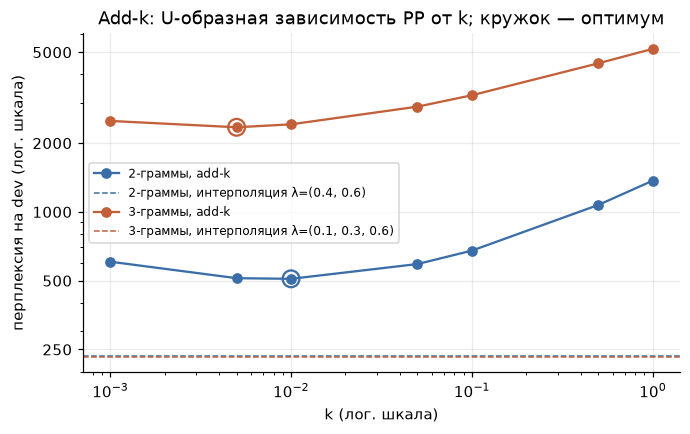

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
for n, color in [(2, MAIN), (3, "#C2603A")]:
    ks = sorted(k_curves[n])
    pps = [k_curves[n][k] for k in ks]
    ax.plot(ks, pps, marker="o", color=color, label=f"{n}-граммы, add-k")
    ax.scatter([best[n]["k"]], [k_curves[n][best[n]["k"]]], s=120, facecolors="none", edgecolors=color, linewidths=1.5)
    l_best = best[n]["lambdas"]
    pp_interp = next(r["PP (dev)"] for r in tuning_rows if r["n"] == n and r["параметр"] == str(l_best))
    ax.axhline(pp_interp, color=color, linestyle="--", linewidth=1, label=f"{n}-граммы, интерполяция λ={l_best}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_yticks([250, 500, 1000, 2000, 5000])
ax.yaxis.set_major_formatter(plt.ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("k (лог. шкала)")
ax.set_ylabel("перплексия на dev (лог. шкала)")
ax.set_title("Add-k: U-образная зависимость PP от k; кружок — оптимум")
ax.legend(fontsize=8)
plt.show()


### 8.2. Перплексия на Test: без сглаживания vs со сглаживанием

In [30]:
models = {n: NGramLM(n, VOCAB).fit(train_lm) for n in (2, 3)}

result_rows = []
for n, lm in models.items():
    _, n_tok, zeros = lm.log_likelihood(test_lm, mode="mle")
    result_rows.append({"n": n, "метод": "без сглаживания (MLE)", "параметры": "—",
                        "PP (test)": lm.perplexity(test_lm, mode="mle"),
                        "нулевых событий": f"{zeros} из {n_tok} ({100*zeros/n_tok:.1f}%)"})
    result_rows.append({"n": n, "метод": "Лаплас (add-1)", "параметры": "k=1",
                        "PP (test)": lm.perplexity(test_lm, mode="addk", k=1.0), "нулевых событий": "0"})
    result_rows.append({"n": n, "метод": "add-k (подобранный)", "параметры": f"k={best[n]['k']}",
                        "PP (test)": lm.perplexity(test_lm, mode="addk", k=best[n]["k"]), "нулевых событий": "0"})
    result_rows.append({"n": n, "метод": "интерполяция (подобранная)", "параметры": f"λ={best[n]['lambdas']}",
                        "PP (test)": lm.perplexity(test_lm, mode="interp", lambdas=best[n]["lambdas"]), "нулевых событий": "0"})

results = pd.DataFrame(result_rows)
results["PP (test)"] = results["PP (test)"].map(lambda x: "∞" if math.isinf(x) else f"{x:.1f}")
results

,n,метод,параметры,PP (test),нулевых событий
0,2,без сглаживания (MLE),—,∞,13726 из 42701 (32.1%)
1,2,Лаплас (add-1),k=1,1469.4,0
2,2,add-k (подобранный),k=0.01,529.1,0
3,2,интерполяция (подобранная),"λ=(0.4, 0.6)",243.0,0
4,3,без сглаживания (MLE),—,∞,29333 из 42701 (68.7%)
5,3,Лаплас (add-1),k=1,5604.7,0
6,3,add-k (подобранный),k=0.005,2446.6,0
7,3,интерполяция (подобранная),"λ=(0.1, 0.3, 0.6)",239.6,0


In [31]:
# Для наглядности: перплексия MLE "только на виденных N-граммах" — насколько модель уверена там, где вообще может ответить
for n, lm in models.items():
    logp, n_tok, zeros = lm.log_likelihood(test_lm, mode="mle")
    pp_seen = math.exp(-logp / (n_tok - zeros))
    print(f"n={n}: MLE-перплексия только по {n_tok - zeros} виденным событиям = {pp_seen:.1f}; "
          f"но {zeros} событий ({100*zeros/n_tok:.1f}%) имеют P=0 ⇒ итоговая PP = ∞")

# Вклад [UNK]: это самый частый «токен», его легко предсказать, и он занижает PP
for n, lm in models.items():
    lam = best[n]["lambdas"]
    p_unk = lm._p_mle(1, (), "[UNK]")
    logp_all = logp_known = 0.0
    n_all = n_known = 0
    for d in test_lm:
        toks = lm._pad(d)
        for i in range(n - 1, len(toks)):
            lp = math.log(lm.prob(toks[i - n + 1:i], toks[i], mode="interp", lambdas=lam))
            logp_all += lp
            n_all += 1
            if toks[i] != "[UNK]":
                logp_known += lp
                n_known += 1
    print(f"n={n}: P_unigram([UNK]) = {p_unk:.3f}; интерполяция: PP по всем токенам = {math.exp(-logp_all / n_all):.1f}, "
          f"PP только по токенам ≠ [UNK] = {math.exp(-logp_known / n_known):.1f}")

n=2: MLE-перплексия только по 28975 виденным событиям = 50.8; но 13726 событий (32.1%) имеют P=0 ⇒ итоговая PP = ∞
n=3: MLE-перплексия только по 13368 виденным событиям = 17.6; но 29333 событий (68.7%) имеют P=0 ⇒ итоговая PP = ∞
n=2: P_unigram([UNK]) = 0.154; интерполяция: PP по всем токенам = 243.0, PP только по токенам ≠ [UNK] = 665.9
n=3: P_unigram([UNK]) = 0.154; интерполяция: PP по всем токенам = 239.6, PP только по токенам ≠ [UNK] = 649.3


**Математический вывод.**

1. *Без сглаживания* оценка максимального правдоподобия присваивает **нулевую** вероятность любой $N$-грамме, которой не было в Train. В Test такие $N$-граммы неизбежны (см. долю нулевых событий выше — для триграмм это большинство токенов). Одного нуля достаточно: $\log 0 = -\infty$, сумма log-likelihood равна $-\infty$, перплексия $= e^{+\infty} = \infty$. Модель без сглаживания **формально непригодна** для оценки новых текстов — независимо от того, насколько хорошо она предсказывает виденные N-граммы.

2. *Аддитивное сглаживание* «отбирает» массу у виденных событий и распределяет её на все $|V|$ исходов. При $k=1$ (Лаплас) для триграмм это катастрофично: почти каждый контекст $h$ встречался считанные разы, а знаменатель прирастает на $k|V|$, где $|V| = 11\,501$ (все токены словаря, кроме `<s>`, который не предсказывается), так что $P(w\mid h) \approx 1/|V|$ для всего — модель почти равномерная, перплексия огромная. Уменьшение $k$ (подобрано на dev) резко снижает перплексию, потому что меньше массы уходит на невиденные события.

3. *Интерполяция* даёт лучшие результаты, потому что невиденная триграмма не получает «равномерную» массу, а **отступает** к биграмме и униграмме — то есть использует информацию о том, какие слова вообще частотны и что обычно следует за последним словом контекста. Это и есть суть сглаживания: перераспределять вероятность **осмысленно**, а не равномерно.

4. Триграммы vs биграммы: при таком объёме корпуса (~6 тыс. коротких документов) триграммная модель страдает от разреженности — доля невиденных триграмм в Test более чем вдвое выше, чем биграмм, поэтому при аддитивном сглаживании триграммы сильно проигрывают биграммам. Интерполяция это компенсирует: триграммная модель, откатывающаяся к биграммам и униграммам, даёт перплексию чуть ниже биграммной. Показательно, что подобранные веса $\lambda$ отдают наибольшую массу **униграммам** — сигнал о том, что для этого корпуса контексты слишком разрежены, и модель большую часть времени вынуждена опираться на частоты отдельных слов.

5. *Оговорка о сравнимости.* Перплексия зависит от словаря: все слова с частотой 1 свёрнуты в `[UNK]`, а это самый частый «токен» (~15% Train, ~21% Test). Предсказать его легко, поэтому общая PP **ниже**, чем PP по настоящим словам (см. вывод выше). Значит, PP ≈ 240 — не абсолютная мера качества: при другом пороге `MIN_FREQ` получились бы другие числа. Сравнивать перплексии можно только у моделей **с одинаковым словарём** — у нас это так, поэтому сравнение методов сглаживания честное. Частотный `[UNK]` отчасти объясняет и большой вес униграмм $\lambda_1$.


## 9. Генерация текстов (марковская цепь)

Генерация начинается с контекста из токенов `<s>` и на каждом шаге сэмплирует следующее слово из распределения $P(w\mid h)$ обученной модели (используем счётчики без сглаживания — это и есть марковская цепь по наблюдённым переходам). Останавливаемся на `</s>` или по достижении `max_len = 30` токенов.

In [32]:
MAX_LEN = 30
rng = random.Random(SEED)

for n in (3, 2):
    print(f"===== {n}-граммная модель =====")
    for i in range(5):
        print(f"{i+1}. <s> {models[n].generate(rng, max_len=MAX_LEN)} </s>")
    print()

===== 3-граммная модель =====
1. <s> никто не сможет пиздеть на [UNK] приехала чтобы [UNK] в [UNK] нигеров [UNK] хотя даже на это тупоголовое еблище [UNK] [UNK] лол </s>
2. <s> я понимаю анончики что я щас оторву тебе голову не [UNK] про пиписьки с радио свобода вот поэтому это нихуя не сделаешь и будешь искать хохлов под кроватью меня блять </s>
3. <s> конкретно тебе выше уже [UNK] [UNK] бы сам институт измены не изобрели [UNK] беда если блядь то баба [UNK] [UNK] и буду душить ее [UNK] одна история охуительнее другой просто </s>
4. <s> полно [UNK] влияния [UNK] во главе нигр пытаются победить [UNK] угрозу тред [UNK] аннексию чехословакии высер шлюхи </s>
5. <s> хер ты где на [UNK] [UNK] [NUM] кг за счет [UNK] пусть и больше [UNK] дебил </s>

===== 2-граммная модель =====
1. <s> ебать ты капчуешь немедленно отдай хачу [UNK] да и отрицать это мне похуй по три назад в случае с первого раза не как то [UNK] последняя конченая и нассу твоей </s>
2. <s> а то отправил не стыдно писать для [UN

**Оценка сгенерированных текстов** (подробнее — в README):
- *Триграммы*: локально (в окне 2–3 слов) фразы почти всегда грамматичны и звучат «как настоящие» реплики форума — согласование прилагательное–существительное и предлог–падеж чаще всего соблюдено, потому что каждый переход буквально скопирован из корпуса. Но на дистанции больше 3–4 слов смысл теряется: тема прыгает, подлежащее меняется, предложение не завершается логически.
- *Биграммы*: разнообразнее (меньше «переписывания» целых фраз из корпуса), но грамматическая связность хуже — согласование держится только между соседними словами.
- Токены `[NUM]` и `[UNK]` появляются в правдоподобных позициях («[NUM] кг», «на [UNK]»), что подтверждает пользу замены шума спец-токенами вместо удаления.
- Марковская модель порядка 2–3 не имеет памяти о начале предложения и никакой семантики — это ожидаемая граница метода, из-за которой в современных системах используют нейросетевые модели с длинным контекстом.

## 10. Итоги

| Шаг | Результат |
|---|---|
| Разбиение | 80/20 со стратификацией по `target_group`, дубликаты удалены до сплита |
| Шум | URL/HTML отсутствуют (доказано регулярками); найдены числа, капс, эмоциональная пунктуация, латиница, растянутые буквы, скобочные смайлы, @ как разделитель паст, маскировка латиницей, «эхо» (((…))), эмодзи, типографика |
| Очистка | 18 правил на `re`, спец-токены `[NUM] [LAT] [EMPH] [SMILE] [SAD] [ECHO] [EMOJI] [USER] [EMAIL] [TAG] [URL]`, обёртка `<s> … </s>` |
| Нормализация | стемминг сокращает словарь сильнее, лемматизация точнее; на сленге оба слабы |
| Левенштейн | двухстрочная реализация O(min(n,m)) памяти, индекс удалений для поиска кандидатов; найдены опечатки, словоформы и «ложные друзья» |
| Языковая модель | явный словарь (freq ≥ 2) + `[UNK]`; MLE / add-k / интерполяция; PP = ∞ без сглаживания, конечная — со сглаживанием |
| Генерация | 5 текстов от `<s>` до `</s>`, локально грамматичны, глобально бессвязны |